# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ayustar/flyrank-ml-internship-starter/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

Archetype (rule-based, from observable signals)	Reason code	Action
Stale but visible	stale_visible_page	Refresh content: update facts, add missing subtopics
Visible, ranks well, few clicks	low_ctr_visible_page	Rewrite title/meta and snippet
Thin but visible	thin_visible_page	Expand with missing subtopics, not padding
Visited but not engaging	low_engagement_visible_page	Improve scanability and structure
Everything else	no_flag	Monitor

These archetypes are defined by transparent rules, not clustering, so each one can be inspected. Each page gets one reason code (first match). Priority = 60% model decline risk + 40% visibility at stake.

In [14]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import os, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier

if not os.path.exists("data/raw/content_refresh_anonymized.csv"):
    !git clone https://github.com/Ayustar/flyrank-ml-internship-starter.git
    %cd flyrank-ml-internship-starter

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
df = df[(df["impressions_90d"] > 0) & (df["content_age_days"] >= 90)]
df = df.drop_duplicates("content_id").reset_index(drop=True)
df["is_down"] = (df["trend_direction"] == "down").astype(int)   # evaluation only, never a score input

# features + the same leak audit as Week 6
banned = ("trend", "label", "is_down", "score", "priority", "health", "flag", "action",
          "last_30d", "prev_30d")
features = [c for c in df.select_dtypes("number").columns
            if c not in ("content_id", "client_id")
            and not any(b in c.lower() for b in banned)]
aucs = {}
for c in features:
    a = roc_auc_score(df["is_down"], df[c].fillna(df[c].median()))
    aucs[c] = max(a, 1 - a)
leaks = list(pd.Series(aucs)[pd.Series(aucs) > 0.75].index)
clean = [c for c in features if c not in leaks]
print("leak columns removed:", leaks)
print("features used:", len(clean))

# every page is scored by a model that never saw its client (5-fold, grouped by client)
oof = np.zeros(len(df))
for tr, te in GroupKFold(n_splits=5).split(df, df["is_down"], groups=df["client_id"]):
    med = df.loc[tr, clean].median()
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)
    rf.fit(df.loc[tr, clean].fillna(med), df.loc[tr, "is_down"])
    oof[te] = rf.predict_proba(df.loc[te, clean].fillna(med))[:, 1]
df["risk"] = oof

def p_at_k(y, s, k):
    return y[np.argsort(-s, kind="stable")[:k]].mean()

y = df["is_down"].values
metrics = {"n_pages": len(df), "base_decline_rate": round(float(y.mean()), 3),
           "grouped_oof_auc": round(float(roc_auc_score(y, oof)), 3),
           "grouped_oof_ap": round(float(average_precision_score(y, oof)), 3),
           "grouped_oof_p_at_50": round(float(p_at_k(y, oof, 50)), 3),
           "leak_columns_removed": leaks}
print(metrics)

leak columns removed: []
features used: 23
{'n_pages': 30000, 'base_decline_rate': 0.542, 'grouped_oof_auc': 0.687, 'grouped_oof_ap': 0.687, 'grouped_oof_p_at_50': 0.58, 'leak_columns_removed': []}


In [15]:
need = ["days_since_last_update", "impressions_90d", "avg_position", "ctr",
        "word_count", "sessions_90d", "engagement_rate", "scroll_rate"]
print("missing columns:", [c for c in need if c not in df.columns])

# ONE reason code per page, first match wins (ctr is a percent, e.g. 0.5 = 0.5%)
conds = [
    (df["days_since_last_update"] >= 90) & (df["impressions_90d"] >= 500),
    df["avg_position"].between(1, 20) & (df["impressions_90d"] >= 500) & (df["ctr"] < 0.5),
    df["word_count"].between(1, 1199) & (df["impressions_90d"] >= 250),
    (df["sessions_90d"] >= 30) & ((df["engagement_rate"] < 30) | (df["scroll_rate"] < 30)),
]
codes   = ["stale_visible_page", "low_ctr_visible_page", "thin_visible_page", "low_engagement_visible_page"]
actions = ["refresh content", "rewrite title/meta and snippet",
           "expand with missing subtopics", "improve scanability and structure"]
df["reason_code"] = np.select(conds, codes, default="no_flag")
df["action"] = np.select(conds, actions, default="monitor")

# priority = model risk (60%) + visibility at stake (40%)
vis = np.log1p(df["impressions_90d"]) / np.log1p(df["impressions_90d"].max())
df["priority"] = (100 * (0.6 * df["risk"] + 0.4 * vis)).round(1)
df["confidence"] = np.select(
    [(df["risk"] >= 0.65) & (df["impressions_90d"] >= 500) & (df["sessions_90d"] >= 10),
     df["risk"] >= 0.50], ["high", "medium"], default="low")

queue = (df[df["reason_code"] != "no_flag"].sort_values("priority", ascending=False)
           .reset_index(drop=True))
queue["rank"] = queue.index + 1

print("queue size:", len(queue), "of", len(df))
print(queue.groupby(["reason_code", "action"]).agg(
    pages=("content_id", "count"), mean_risk=("risk", "mean"),
    mean_impressions=("impressions_90d", "mean")).round(2))
print(queue[["rank", "reason_code", "action", "priority", "risk", "confidence",
             "impressions_90d", "days_since_last_update"]].head(10))

missing columns: []
queue size: 14533 of 30000
                                                               pages  \
reason_code                 action                                     
low_ctr_visible_page        rewrite title/meta and snippet      6216   
low_engagement_visible_page improve scanability and structure   1690   
stale_visible_page          refresh content                     6575   
thin_visible_page           expand with missing subtopics         52   

                                                               mean_risk  \
reason_code                 action                                         
low_ctr_visible_page        rewrite title/meta and snippet          0.61   
low_engagement_visible_page improve scanability and structure       0.49   
stale_visible_page          refresh content                         0.57   
thin_visible_page           expand with missing subtopics           0.61   

                                                               

                n   rate
age_bucket              
90-179d     12014  0.626
180-269d     4513  0.595
270-364d     7113  0.470
365d+        6360  0.426
                  n   rate
stale_bucket              
0-29d         20480  0.511
30-89d          175  0.589
90-179d        9171  0.611
180d+           174  0.471


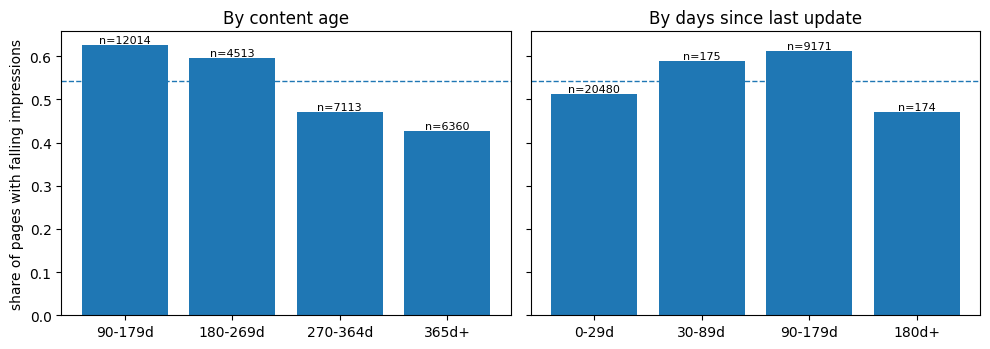

In [16]:
os.makedirs("work/figures", exist_ok=True)
df["age_bucket"] = pd.cut(df["content_age_days"], [90, 180, 270, 365, 10_000],
                          labels=["90-179d", "180-269d", "270-364d", "365d+"], right=False)
df["stale_bucket"] = pd.cut(df["days_since_last_update"], [0, 30, 90, 180, 10_000],
                            labels=["0-29d", "30-89d", "90-179d", "180d+"], right=False)
a = df.groupby("age_bucket", observed=True)["is_down"].agg(n="count", rate="mean")
s = df.groupby("stale_bucket", observed=True)["is_down"].agg(n="count", rate="mean")
print(a.round(3)); print(s.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for axis, t, title in [(ax[0], a, "By content age"), (ax[1], s, "By days since last update")]:
    bars = axis.bar(t.index.astype(str), t["rate"])
    for b, n in zip(bars, t["n"]):
        axis.text(b.get_x() + b.get_width() / 2, b.get_height(), f"n={n}", ha="center", va="bottom", fontsize=8)
    axis.axhline(df["is_down"].mean(), ls="--", lw=1)
    axis.set_title(title)
ax[0].set_ylabel("share of pages with falling impressions")
plt.tight_layout()
plt.savefig("work/figures/decay_by_age_and_staleness.png", dpi=150)
plt.show()

## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

Intended use: decision support. The queue suggests which pages a human editor should look at first this week. It is not an automatic edit list.

Limits:

The target is a current-window proxy (trend_direction == "down"), not a future outcome.
The data is a 30k-page starter slice. Results are directional, not a benchmark on the full warehouse.
A high rank means “worth reviewing first”, not “will recover if edited”.
The model measures association in observed data. It cannot show that any action causes improvement.
Declines can come from consolidation, seasonality, or SERP changes that the model cannot see.

In [17]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

Human review rules: an editor checks every queued page before any change. Before acting, check: (1) is the drop real over a longer window? (2) did a related page absorb its demand? (3) is it seasonal? (4) does the action fit the page’s purpose? A page is only approved when a reviewer writes one line of reasoning.

What should NOT be automated (no-go list):

Publishing or rewriting content directly from the queue
Deleting, merging, or redirecting pages
Changing titles or meta descriptions in bulk
Treating confidence = high as permission to skip review
Reporting a refresh as the cause of any later recovery without a controlled test
Using the queue on a new client without checking the data first

In [18]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
capacity, minutes_per_page = 50, 10      # ASSUMPTIONS: a reviewer checks 50 pages, ~10 min each
top = queue.head(capacity)
base = df["is_down"].mean()
hit = top["is_down"].mean()
print(f"review cost: ~{capacity * minutes_per_page / 60:.1f} hours per cycle (assumption-based)")
print(f"top-{capacity} decline rate: {hit:.3f} vs base {base:.3f}")
print(f"extra declining pages surfaced vs random picking: ~{(hit - base) * capacity:.1f} per cycle")
metrics["queue_size"] = int(len(queue))
metrics["top50_decline_rate"] = round(float(hit), 3)

review cost: ~8.3 hours per cycle (assumption-based)
top-50 decline rate: 0.700 vs base 0.542
extra declining pages surfaced vs random picking: ~7.9 per cycle


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

Light monitoring (monthly, manual):

Re-score the previous top 50 and compare their decline rate with the base rate.
Track the base decline rate and the share of missing values in key columns.

Retrain / re-review triggers (policy choices, adjust with experience):

Top-50 decline rate falls more than 10 points below the value measured in this notebook
Base decline rate shifts by more than 5 points
A new client is added, or a key column changes its definition
More than 10% of pages in a key column are missing
Reviewers reject more than half of a cycle’s queue as wrong picks

Non-production: nothing here runs automatically.

In [19]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*



In [20]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
out_cols = ["rank", "content_id", "priority", "risk", "reason_code", "action", "confidence",
            "impressions_90d", "days_since_last_update", "avg_position", "ctr"]
os.makedirs("work/outputs", exist_ok=True)
queue[out_cols].to_csv("work/outputs/ranked_action_queue.csv", index=False)
json.dump(metrics, open("work/outputs/w07_playbook_metrics.json", "w"), indent=2)
print(os.listdir("work/outputs"), os.listdir("work/figures"))


['w08_paper_results.json', 'ranked_action_queue.csv', 'w07_playbook_metrics.json'] ['decay_by_age_and_staleness.png']


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

In [21]:
from sklearn.model_selection import KFold

# baseline (Week-4 rule) on the same pages and metrics
stale_p = (df["days_since_last_update"] / 180).clip(upper=1)
base_score = np.where((df["days_since_last_update"] >= 90) & (df["impressions_90d"] >= 500),
                      100 * (0.5 * stale_p + 0.5 * vis), 0)

# the same model under a random split, to show what a looser design does
oof_r = np.zeros(len(df))
for tr, te in KFold(n_splits=5, shuffle=True, random_state=42).split(df):
    med = df.loc[tr, clean].median()
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)
    m.fit(df.loc[tr, clean].fillna(med), df.loc[tr, "is_down"])
    oof_r[te] = m.predict_proba(df.loc[te, clean].fillna(med))[:, 1]

def tab(t):
    return [{"label": str(i), "n": int(r.n), "rate": round(float(r.rate), 3)} for i, r in t.iterrows()]

results = {
    "n_pages": int(len(df)), "n_features": len(clean), "leaks": leaks,
    "base_rate": round(float(y.mean()), 3),
    "model_auc": round(float(roc_auc_score(y, oof)), 3),
    "model_ap": round(float(average_precision_score(y, oof)), 3),
    "model_p50": round(float(p_at_k(y, oof, 50)), 3),
    "base_auc": round(float(roc_auc_score(y, base_score)), 3),
    "base_p50": round(float(p_at_k(y, base_score, 50)), 3),
    "random_cv_auc": round(float(roc_auc_score(y, oof_r)), 3),
    "random_cv_p50": round(float(p_at_k(y, oof_r, 50)), 3),
    "queue_size": int(len(queue)),
    "age": tab(a), "stale": tab(s),
    "reasons": [{"code": c, "action": ac, "pages": int(n)} for (c, ac), n in
                queue.groupby(["reason_code", "action"]).size().items()],
    "top10": [{"rank": int(r["rank"]), "reason_code": r["reason_code"], "action": r["action"],
               "confidence": r["confidence"], "impressions": int(r["impressions_90d"]),
               "days_stale": int(r["days_since_last_update"])} for _, r in queue.head(10).iterrows()],
}
os.makedirs("docs", exist_ok=True)
json.dump(results, open("docs/results.json", "w"), indent=1)
json.dump(results, open("work/outputs/w08_paper_results.json", "w"), indent=1)
print({k: v for k, v in results.items() if k not in ("age", "stale", "reasons", "top10")})

{'n_pages': 30000, 'n_features': 23, 'leaks': [], 'base_rate': 0.542, 'model_auc': 0.687, 'model_ap': 0.687, 'model_p50': 0.58, 'base_auc': 0.53, 'base_p50': 0.58, 'random_cv_auc': 0.778, 'random_cv_p50': 1.0, 'queue_size': 14533}


In [22]:
import os
print("working folder:", os.getcwd())
print("docs exists:", os.path.exists("docs"))
print("results.json exists:", os.path.exists("docs/results.json"))
print("variables ready:", all(v in globals() for v in ["df", "queue", "oof", "clean", "a", "s", "leaks"]))

working folder: /content/flyrank-ml-internship-starter
docs exists: True
results.json exists: True
variables ready: True


In [23]:
rf_all = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
med = df[clean].median()
rf_all.fit(df[clean].fillna(med), df["is_down"])
imp = pd.Series(rf_all.feature_importances_, index=clean).sort_values(ascending=False)
print(imp.head(10).round(3))
print("\nname-based suspects:", [c for c in clean if any(w in c.lower() for w in
      ("30", "prev", "prior", "last", "recent", "change", "delta", "growth", "pct", "wow", "mom"))])
print("\nall features:", clean)

avg_position             0.122
impressions_90d          0.116
days_with_impressions    0.115
content_age_days         0.090
char_count               0.061
word_count               0.058
ctr                      0.046
scroll_rate              0.041
pageviews_90d            0.037
clicks_90d               0.035
dtype: float64

name-based suspects: ['days_since_last_update', 'ai_traffic_pct']

all features: ['search_volume', 'competition', 'cpc', 'word_count', 'char_count', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'content_age_days', 'age_tier_order', 'days_since_last_update', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct']
